# Inspect normalized Mask R-CNN dataset images

Set `DATASET_DIR` to a directory of Mask R-CNN `.npz` tiles and adjust `SAMPLE_INDEX` to inspect another tile. Each tile is expected to contain `image`, `labels`, `layer_names`, and `res` arrays. The notebook computes the normalization statistics required by `MaskRCNNDataset`, initializes the dataset with `augment=False`, and plots its normalized `DEM`, `SLOPE`, `RR`, and `LAPLACE` channels.

In [56]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

REPO_ROOT = Path.cwd().resolve()
while REPO_ROOT != REPO_ROOT.parent and not (REPO_ROOT / "code" / "modelling" / "MaskRCNN.py").exists():
    REPO_ROOT = REPO_ROOT.parent
CODE_DIR = REPO_ROOT / "code"
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from modelling.MaskRCNN import MaskRCNNDataset

DATASET_DIR = Path('/Users/wm722/Documents/SCDs/data/dataset/')
SAMPLE_INDEX = 0
NORM_SAMPLE_PIXELS = 10000


In [57]:
paths = sorted(DATASET_DIR.glob("*.npz"))
if not paths:
    raise FileNotFoundError(f"No .npz tiles found in {DATASET_DIR}")
if not 0 <= SAMPLE_INDEX < len(paths):
    raise IndexError(f"SAMPLE_INDEX must be between 0 and {len(paths) - 1}")

print(f"Found {len(paths)} tiles")
print(f"Selected: {paths[SAMPLE_INDEX]}")


Found 905 tiles
Selected: /Users/wm722/Documents/SCDs/data/dataset/Australia_negative_317564_6662101_321405_6665942.npz


In [58]:
def robust_stats(values):
    values = np.asarray(values, dtype=np.float32)
    values = values[np.isfinite(values)]
    if values.size == 0:
        raise ValueError("No finite values available for normalization statistics")
    values = np.clip(values, *np.percentile(values, [1, 99]))
    median = float(np.median(values))
    q25, q75 = np.percentile(values, [25, 75])
    iqr = float(q75 - q25)
    if iqr == 0:
        raise ValueError("Normalization IQR is zero")
    return {"median": median, "iqr": iqr}


samples = {name: [] for name in ("DEM", "SLOPE", "RR", "LAPLACE")}
resolutions = []

for path in paths:
    with np.load(path, allow_pickle=True) as data:
        layer_names = [str(name) for name in data["layer_names"]]
        layer_index = {name: index for index, name in enumerate(layer_names)}
        image = data["image"].astype(np.float32, copy=False)
        valid = np.isfinite(image[layer_index["DEM"]])
        if not valid.any():
            continue

        chosen = np.flatnonzero(valid.ravel())
        if chosen.size > NORM_SAMPLE_PIXELS:
            chosen = np.random.default_rng(42).choice(chosen, NORM_SAMPLE_PIXELS, replace=False)

        dem = image[layer_index["DEM"]]
        dem_median = np.median(dem[valid])
        samples["DEM"].append((dem.ravel()[chosen] - dem_median))
        samples["SLOPE"].append(np.power(image[layer_index["DEM_SLOPE"]].ravel()[chosen], 0.25))
        samples["RR"].append(image[layer_index["RR"]].ravel()[chosen])
        samples["LAPLACE"].append(image[layer_index["LAPLACE"]].ravel()[chosen])
        resolutions.append(float(data["res"]))

norm_stats = {name: robust_stats(np.concatenate(values)) for name, values in samples.items()}
norm_stats["max_res"] = float(max(resolutions))
norm_stats


{'DEM': {'median': -0.001491546630859375, 'iqr': 9.141386032104492},
 'SLOPE': {'median': 0.960578441619873, 'iqr': 0.45525020360946655},
 'RR': {'median': 0.006635916419327259, 'iqr': 0.38608137518167496},
 'LAPLACE': {'median': 0.0, 'iqr': 0.0599365234375},
 'max_res': 30.0}

In [74]:
dataset = MaskRCNNDataset(paths, norm_stats=norm_stats, augment=False)
image, target = dataset[602]

channel_names = ["DEM", "SLOPE", "RR", "LAPLACE"]
print("path:", paths[521])
print("image shape:", tuple(image.shape))
print("target keys:", sorted(target))
print("resolution value:", target["resolution"].item())
print("instances:", len(target["labels"]))
print("boxes:\n", target["boxes"])
for name, channel in zip(channel_names, image.numpy()):
    print(f"{name}: min={channel.min():.3f}, median={np.median(channel):.3f}, max={channel.max():.3f}")


path: /Users/wm722/Documents/SCDs/data/dataset/Nebraska_positive_564819_4476819_575059_4487059.npz
image shape: (4, 512, 512)
target keys: ['area', 'boxes', 'image_id', 'iscrowd', 'labels', 'masks', 'resolution']
resolution value: 0.6634533405303955
instances: 0
boxes:
 tensor([], size=(0, 4))
DEM: min=-1.644, median=0.000, max=1.256
SLOPE: min=-1.186, median=-0.121, max=1.535
RR: min=-2.987, median=-0.004, max=2.497
LAPLACE: min=-3.682, median=-0.007, max=4.029


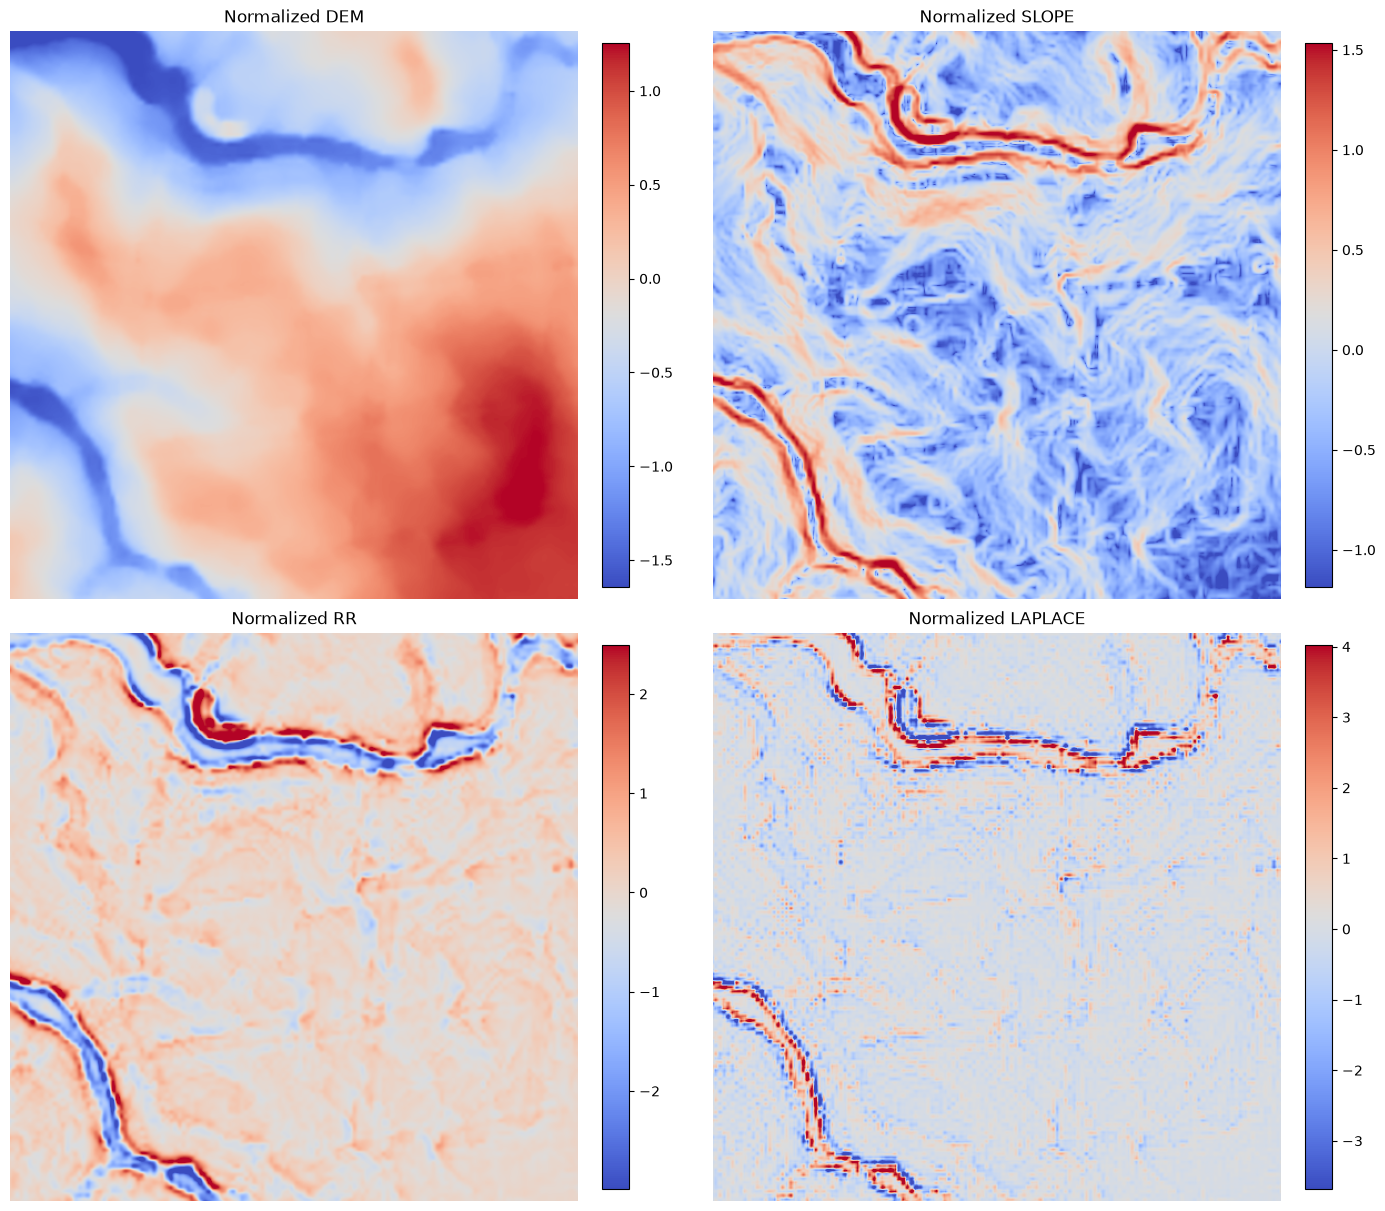

In [75]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12), constrained_layout=True)
for axis, name, channel in zip(axes.flat, channel_names, image.numpy()):
    im = axis.imshow(channel, cmap="coolwarm")
    axis.set_title(f"Normalized {name}")
    axis.axis("off")
    fig.colorbar(im, ax=axis, fraction=0.046, pad=0.04)
plt.show()


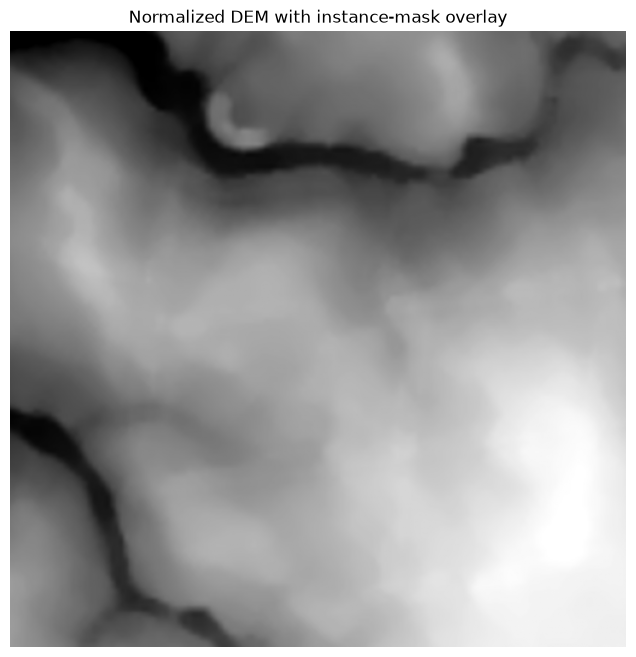

In [76]:
mask = target["masks"].numpy().any(axis=0) if len(target["masks"]) else np.zeros(image.shape[1:], dtype=bool)
fig, axis = plt.subplots(figsize=(8, 8))
axis.imshow(image[0], cmap="gray")
axis.imshow(np.ma.masked_where(~mask, mask), cmap="autumn", alpha=0.45)
axis.set_title("Normalized DEM with instance-mask overlay")
axis.axis("off")
plt.show()
